<a href="https://colab.research.google.com/github/venujaranasinghe/vasicek-bond-risk-simulator/blob/main/notebook/vasicek_bond_risk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Monte Carlo Pricing and Interest-Rate Risk of a Sri Lankan Treasury Bond Using the Vasicek Model

**Summary.** This notebook models the Sri Lankan short-term interest rate with the Vasicek mean-reverting model, calibrated to weekly 91-day Treasury bill yields published by the Central Bank of Sri Lanka. Rate paths are simulated with the Euler–Maruyama scheme, and a 5-year Treasury bond is priced by Monte Carlo as the average discounted value of its cash flows. The same simulator then gives the distribution of the bond's value one year ahead, from which the 95% Value-at-Risk and Expected Shortfall are estimated. All stochastic results are reported over several random seeds with 95% confidence intervals.

In [1]:
# Cell 1: packages (already present on Colab; the install line makes the notebook self-contained)
!pip install -q numpy pandas matplotlib scipy

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import brentq

print("numpy", np.__version__, "| pandas", pd.__version__)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})
T_START = time.time()

numpy 2.4.6 | pandas 2.2.3


## 2. Problem and question

Treasury bonds are a core holding of Sri Lankan banks, pension funds and individual investors. Their prices fall when interest rates rise, and Sri Lankan rates have been extremely volatile: the 91-day Treasury bill yield rose from under 5% in 2020 to above 33% in late 2022, then fell back to single digits in February 2024.

**Question.** What is the fair value of a 5-year Sri Lankan Treasury bond under current rate conditions, and how much value could a holder lose over one year at 95% confidence (Value-at-Risk and Expected Shortfall) if rates rise?

**Scope.** One bond, one risk factor (the short rate), one model (Vasicek). Credit risk, liquidity and taxes are ignored.

## 3. Model, assumptions and equations

### 3.1 Short-rate model

The short rate $r_t$ (per year, continuously compounded) follows the Vasicek stochastic differential equation

$$dr_t = \kappa(\theta - r_t)\,dt + \sigma\,dW_t ,$$

| Symbol | Meaning | Unit |
|---|---|---|
| $r_t$ | short-term interest rate | 1/year |
| $\kappa$ | speed of mean reversion | 1/year |
| $\theta$ | long-run mean rate | 1/year |
| $\sigma$ | volatility of the rate | 1/year$^{3/2}$ (rate per $\sqrt{\text{year}}$) |
| $W_t$ | standard Brownian motion | $\sqrt{\text{year}}$ |

Without the noise term this is the linear ODE $dr/dt = \kappa(\theta - r)$, whose solution decays exponentially towards $\theta$ with half-life $\ln 2/\kappa$.

### 3.2 Calibration (input modelling)

Over a step $\Delta$ the Vasicek model has an exact discrete form, an AR(1) process:

$$r_{t+\Delta} = \underbrace{\theta\,(1-e^{-\kappa\Delta})}_{a} + \underbrace{e^{-\kappa\Delta}}_{b}\, r_t + \varepsilon_t,
\qquad \varepsilon_t \sim \mathcal N\!\left(0,\ \sigma^2\,\frac{1-e^{-2\kappa\Delta}}{2\kappa}\right).$$

Fitting the straight line $r_{t+\Delta} = a + b\,r_t$ by least squares and inverting gives

$$\hat\kappa = -\frac{\ln \hat b}{\Delta},\qquad
\hat\theta = \frac{\hat a}{1-\hat b},\qquad
\hat\sigma = \sqrt{\frac{2\hat\kappa\,\hat s^2}{1-\hat b^{2}}},$$

where $\hat s^2$ is the residual variance. This needs $0<\hat b<1$; otherwise the data show no mean reversion and the model does not apply.

The published 91-day yield $y$ is a simple annualised yield. It is converted to a continuously compounded rate over the bill's life $\tau = 91/365$ years:

$$r = \frac{\ln(1 + y\,\tau)}{\tau}.$$

### 3.3 Simulation (Euler–Maruyama)

With time step $\Delta t$ and independent $Z_n \sim \mathcal N(0,1)$:

$$r_{n+1} = r_n + \kappa(\theta - r_n)\,\Delta t + \sigma\sqrt{\Delta t}\;Z_n .$$

This is Euler's method for the drift plus a random increment for the noise. The deterministic part is stable when $\kappa\,\Delta t < 2$. The scheme has weak order 1: the error in expected values shrinks in proportion to $\Delta t$.

### 3.4 Monte Carlo bond pricing

A zero-coupon bond paying 1 at time $T$ is worth the expected discount factor

$$P(0,T) = \mathbb E\!\left[\exp\!\Big(-\int_0^T r_s\,ds\Big)\right]
\approx \frac1N\sum_{i=1}^{N} \exp\!\Big(-\sum_{n=0}^{M-1} \tfrac12\big(r^{(i)}_n + r^{(i)}_{n+1}\big)\Delta t\Big),$$

with the integral computed by the trapezoidal rule along each of $N$ paths. By the law of large numbers the average converges to the expectation, and by the central limit theorem its standard error is $s/\sqrt N$, giving the 95% confidence interval $\bar x \pm 1.96\,s/\sqrt N$.

A coupon bond with face value $F$, annual coupon rate $c$ and payments every half-year at times $t_1,\dots,t_m=T$ is priced as

$$V_0 = \sum_{j=1}^{m} \frac{cF}{2}\,P(0,t_j) + F\,P(0,T).$$

### 3.5 One-year Value-at-Risk and Expected Shortfall

Let $V_1$ be the value of the position after one year: the price of the remaining cash flows given the simulated rate $r_1$, plus the coupons received during the year. The loss is $L = V_0 - V_1$ (negative $L$ is a gain).

$$\text{VaR}_{95\%} = \text{95th percentile of } L, \qquad
\text{ES}_{95\%} = \mathbb E\big[L \mid L \ge \text{VaR}_{95\%}\big].$$

Revaluing the bond at the horizon would need a second Monte Carlo inside every path. Instead the remaining cash flows are priced by Monte Carlo on a grid of starting rates, using the same random numbers for every grid point, and each path's value is read off by linear interpolation.

### 3.6 Assumptions

1. The 91-day Treasury bill yield is used as a proxy for the instantaneous short rate.
2. Observations are treated as equally spaced, $\Delta = 1/52$ year, although published week-end dates are 6 to 10 days apart.
3. $\kappa$, $\theta$ and $\sigma$ are constant over the calibration window and the life of the bond.
4. The market price of interest-rate risk is zero, so the same parameters are used for pricing and for the one-year risk horizon.
5. The government pays every cash flow in full and on time (no credit risk).
6. Coupons received during the year are held as cash and not reinvested.

### 3.7 Concepts applied

| Part of the model | Concept |
|---|---|
| Average of discounted cash flows over $N$ paths, standard error $\propto N^{-1/2}$, confidence intervals | Monte Carlo integration and the law of large numbers |
| Fitting $\kappa,\theta,\sigma$ to observed yields; Gaussian random variates for $Z_n$ | Input modelling and random variate generation |
| Euler–Maruyama time stepping, stability condition, order of accuracy | Numerical ODE solvers (Euler's method and error orders) |

## 4. Implementation

### 4.1 Parameters

Every setting lives in this one cell.

In [2]:
# Cell 2: all settings, with units

# --- Reproducibility ---
SEED = 42                      # master seed; child seeds are derived from it
N_SEEDS = 10                   # independent replications for confidence intervals

# --- Data ---
DATA_URL = "https://raw.githubusercontent.com/venujaranasinghe/vasicek-bond-risk-simulator/main/data/cbsl_yields_weekly.csv"
LOCAL_FALLBACKS = ["cbsl_yields_weekly.csv", "data/cbsl_yields_weekly.csv", "../data/cbsl_yields_weekly.csv"]
CAL_START = "2024-02-15"       # first date used for calibration (see 4.3)
DT_OBS = 1 / 52                # years between observations (weekly data)
TBILL_TENOR = 91 / 365         # years; life of the 91-day bill

# --- Bond (hypothetical new 5-year Treasury bond) ---
T_BOND = 5.0                   # years to maturity
FACE = 100.0                   # LKR face value
COUPON_RATE = 0.10             # per year, paid in two half-yearly instalments
COUPON_FREQ = 2                # coupon payments per year

# --- Simulation ---
STEPS_PER_YEAR = 52            # Euler-Maruyama steps per year (dt = 1/52 year)
N_PATHS = 100_000              # paths per pricing run

# --- Risk ---
HORIZON = 1.0                  # years
ALPHA = 0.95                   # confidence level
N_OUTER = 50_000               # simulated one-year rate scenarios
N_INNER = 20_000               # paths used to price the bond on the rate grid
N_GRID = 41                    # points in the revaluation grid

### 4.2 Data loading

Weekly yields from the Central Bank of Sri Lanka Data Library, "Rates on Government Securities" (per cent per annum). Blank cells mean no value was published.

In [3]:
# Cell 3: load the data from the public URL (or a local copy when run offline)
def load_yields():
    for src in [DATA_URL] + LOCAL_FALLBACKS:
        try:
            df = pd.read_csv(src, parse_dates=["date"])
            print("Loaded", len(df), "rows from", src)
            return df.sort_values("date").reset_index(drop=True)
        except Exception:
            continue
    raise FileNotFoundError("Could not load cbsl_yields_weekly.csv. Set DATA_URL in Cell 2.")

raw = load_yields()
bills = raw.dropna(subset=["tbill_91"])[["date", "tbill_91"]].reset_index(drop=True)
print("91-day observations:", len(bills), "from", bills.date.min().date(), "to", bills.date.max().date())

Loaded 390 rows from https://raw.githubusercontent.com/venujaranasinghe/vasicek-bond-risk-simulator/main/data/cbsl_yields_weekly.csv
91-day observations: 332 from 2020-01-09 to 2026-07-09


In [4]:
# Cell 4: convert yields to continuously compounded rates and select the calibration window
def to_continuous(y_percent, tenor=TBILL_TENOR):
    # simple annualised yield in % -> continuously compounded rate (1/year)
    y = np.asarray(y_percent, dtype=float) / 100.0
    return np.log1p(y * tenor) / tenor

bills["r"] = to_continuous(bills["tbill_91"])
cal = bills[bills.date >= CAL_START].reset_index(drop=True)
r_obs = cal["r"].to_numpy()
r0 = float(r_obs[-1])          # latest observed short rate = starting point of every simulation

print(f"Calibration window: {cal.date.min().date()} to {cal.date.max().date()} ({len(cal)} weekly observations)")
print(f"Latest 91-day yield: {cal.tbill_91.iloc[-1]:.2f}%  ->  r0 = {r0:.4f} per year (continuous)")

Calibration window: 2024-02-15 to 2026-07-09 (126 weekly observations)
Latest 91-day yield: 10.21%  ->  r0 = 0.1008 per year (continuous)


### 4.3 The data and the calibration window

The full series shows the 2022 to 2023 crisis. A model with constant parameters cannot describe both the crisis and the period after it, so calibration starts on 15 February 2024, the first week in which the 91-day yield was back in single digits. The effect of this choice is studied in Section 6.

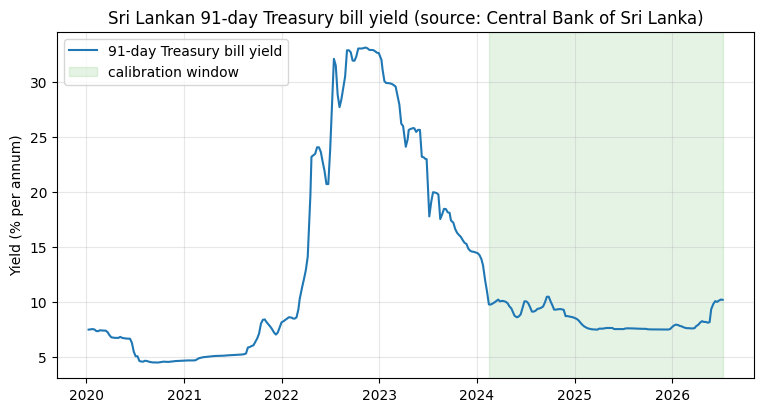

In [5]:
# Cell 5: plot the series and the window
fig, ax = plt.subplots()
ax.plot(bills.date, bills.tbill_91, lw=1.5, label="91-day Treasury bill yield")
ax.axvspan(pd.Timestamp(CAL_START), bills.date.max(), color="tab:green", alpha=0.12, label="calibration window")
ax.set_ylabel("Yield (% per annum)")
ax.set_title("Sri Lankan 91-day Treasury bill yield (source: Central Bank of Sri Lanka)")
ax.legend()
plt.show()

### 4.4 Calibration

In [6]:
# Cell 6: fit the AR(1) line and invert it to Vasicek parameters
def calibrate_vasicek(r, dt):
    # r: observed rates (1/year), equally spaced dt years apart
    x, y = r[:-1].ravel(), r[1:].ravel()        # also accepts several paths as columns
    b, a = np.polyfit(x, y, 1)                     # least-squares line y = a + b x
    if not 0.0 < b < 1.0:
        raise ValueError(f"AR(1) slope b = {b:.4f} is outside (0, 1): no mean reversion in this window.")
    resid = y - (a + b * x)
    s2 = resid.var(ddof=2)                         # residual variance (two fitted coefficients)
    kappa = -np.log(b) / dt                        # 1/year
    theta = a / (1.0 - b)                          # 1/year
    sigma = np.sqrt(2.0 * kappa * s2 / (1.0 - b**2))
    return kappa, theta, sigma, {"a": a, "b": b, "resid": resid}

kappa, theta, sigma, fit = calibrate_vasicek(r_obs, DT_OBS)
print(f"kappa = {kappa:.3f} per year   (half-life {np.log(2)/kappa*12:.1f} months)")
print(f"theta = {theta:.4f} per year  ({theta*100:.2f}%)")
print(f"sigma = {sigma:.4f} per sqrt(year)")
print(f"Stability of Euler-Maruyama: kappa*dt = {kappa/STEPS_PER_YEAR:.4f}  (must be < 2)")

kappa = 0.766 per year   (half-life 10.9 months)
theta = 0.0862 per year  (8.62%)
sigma = 0.0141 per sqrt(year)
Stability of Euler-Maruyama: kappa*dt = 0.0147  (must be < 2)


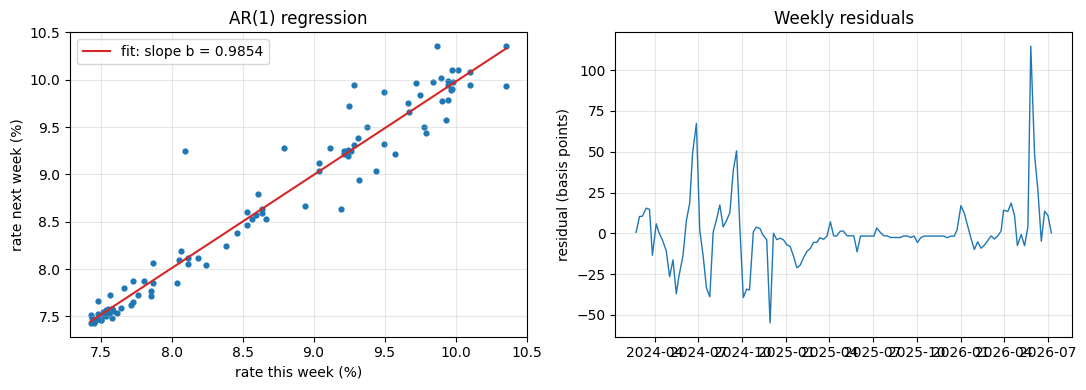

Largest residual: 5.9 standard deviations on 2026-05-27


In [7]:
# Cell 7: how well does the straight line fit?
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x = r_obs[:-1]
axes[0].scatter(x * 100, r_obs[1:] * 100, s=12)
xs = np.array([x.min(), x.max()])
axes[0].plot(xs * 100, (fit["a"] + fit["b"] * xs) * 100, color="tab:red", label=f"fit: slope b = {fit['b']:.4f}")
axes[0].set_xlabel("rate this week (%)"); axes[0].set_ylabel("rate next week (%)"); axes[0].legend()
axes[0].set_title("AR(1) regression")
axes[1].plot(cal.date.iloc[1:], fit["resid"] * 1e4, lw=1)
axes[1].set_ylabel("residual (basis points)"); axes[1].set_title("Weekly residuals")
plt.tight_layout(); plt.show()
z = fit["resid"] / fit["resid"].std(ddof=2)
print(f"Largest residual: {np.abs(z).max():.1f} standard deviations on {cal.date.iloc[1 + np.abs(z).argmax()].date()}")

### 4.5 Rate-path simulator (Euler–Maruyama)

One function does all the simulation. It steps the rate forward, accumulates $\int r\,dt$ with the trapezoidal rule, and returns the discount factors at the requested times, so full paths never need to be stored.

In [8]:
# Cell 8: the simulator
def simulate(r_start, kappa, theta, sigma, times, steps_per_year, n_paths, rng, keep_paths=False, model="vasicek"):
    # model   : "vasicek" (constant volatility) or "cir" (volatility proportional to sqrt(r), Section 6.6)
    # r_start : starting rate (1/year); a scalar, or an array of shape (k, 1) to run k starting
    #           rates on the same random numbers
    # times   : increasing times in years at which discount factors are wanted
    # returns : D with shape (..., n_paths, len(times)), where D = exp(-integral of r from 0 to t)
    #           r_end, the rate at the last time
    #           paths (only if keep_paths), shape (n_steps + 1, n_paths)
    dt = 1.0 / steps_per_year
    step_idx = np.rint(np.asarray(times) * steps_per_year).astype(int)
    assert np.allclose(step_idx / steps_per_year, times), "times must fall on the time grid"
    n_steps = int(step_idx[-1])
    shape = np.broadcast_shapes(np.shape(r_start), (n_paths,))
    r = np.broadcast_to(np.asarray(r_start, dtype=float), shape).copy()
    integral = np.zeros(shape)
    D = np.empty(shape + (len(times),))
    paths = np.empty((n_steps + 1, n_paths)) if keep_paths else None
    if keep_paths:
        paths[0] = r
    j = 0
    sqrt_dt = np.sqrt(dt)
    for n in range(1, n_steps + 1):
        z = rng.standard_normal(n_paths)                               # Z_n ~ N(0, 1)
        if model == "vasicek":
            r_new = r + kappa * (theta - r) * dt + sigma * sqrt_dt * z # Euler-Maruyama step
        else:                                                          # CIR, full-truncation Euler
            rp = np.maximum(r, 0.0)
            r_new = r + kappa * (theta - rp) * dt + sigma * np.sqrt(rp) * sqrt_dt * z
        integral += 0.5 * (r + r_new) * dt                             # trapezoidal rule
        r = r_new
        if keep_paths:
            paths[n] = r
        while j < len(times) and step_idx[j] == n:
            D[..., j] = np.exp(-integral)
            j += 1
    return (D, r, paths) if keep_paths else (D, r)

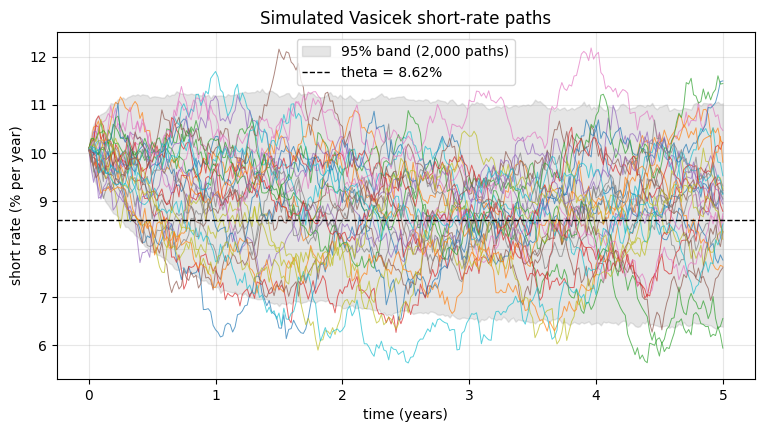

Share of simulated rates below zero: 0.000%


In [9]:
# Cell 9: a few sample paths over the life of the bond
rng_demo = np.random.default_rng(SEED)
_, _, demo = simulate(r0, kappa, theta, sigma, [T_BOND], STEPS_PER_YEAR, 2000, rng_demo, keep_paths=True)
t_axis = np.arange(demo.shape[0]) / STEPS_PER_YEAR
fig, ax = plt.subplots()
ax.plot(t_axis, demo[:, :30] * 100, lw=0.7, alpha=0.7)
lo, hi = np.percentile(demo, [2.5, 97.5], axis=1) * 100
ax.fill_between(t_axis, lo, hi, color="grey", alpha=0.2, label="95% band (2,000 paths)")
ax.axhline(theta * 100, color="k", ls="--", lw=1, label=f"theta = {theta*100:.2f}%")
ax.set_xlabel("time (years)"); ax.set_ylabel("short rate (% per year)")
ax.set_title("Simulated Vasicek short-rate paths"); ax.legend()
plt.show()
print(f"Share of simulated rates below zero: {(demo < 0).mean()*100:.3f}%")

### 4.6 Monte Carlo bond pricing

In [10]:
# Cell 10: cash flows and the pricing function
def bond_cashflows(maturity, face, coupon_rate, freq):
    # returns payment times (years) and amounts (LKR)
    times = np.arange(1, int(round(maturity * freq)) + 1) / freq
    amounts = np.full(len(times), face * coupon_rate / freq)
    amounts[-1] += face
    return times, amounts

def mc_price(r_start, params, times, amounts, n_paths, rng, steps_per_year=STEPS_PER_YEAR, model="vasicek"):
    # returns the Monte Carlo price (LKR), its standard error, and the per-path present values
    D, _ = simulate(r_start, *params, times, steps_per_year, n_paths, rng, model=model)
    pv = D @ amounts                                   # present value of all cash flows, per path
    return pv.mean(axis=-1), pv.std(axis=-1, ddof=1) / np.sqrt(n_paths), pv

params = (kappa, theta, sigma)
cf_times, cf_amounts = bond_cashflows(T_BOND, FACE, COUPON_RATE, COUPON_FREQ)
zero_times, zero_amounts = np.array([T_BOND]), np.array([FACE])
print("Coupon bond payments (time in years: LKR):")
print(", ".join(f"{t:g}: {a:g}" for t, a in zip(cf_times, cf_amounts)))

Coupon bond payments (time in years: LKR):
0.5: 5, 1: 5, 1.5: 5, 2: 5, 2.5: 5, 3: 5, 3.5: 5, 4: 5, 4.5: 5, 5: 105


### 4.7 One-year Value-at-Risk and Expected Shortfall

In [11]:
# Cell 11: risk function
def one_year_risk(r_start, params, times, amounts, v0, rng,
                  horizon=HORIZON, alpha=ALPHA, n_outer=N_OUTER, n_inner=N_INNER, n_grid=N_GRID, model="vasicek"):
    # Step 1: simulate the short rate to the horizon
    _, r_h = simulate(r_start, *params, [horizon], STEPS_PER_YEAR, n_outer, rng, model=model)

    # Step 2: price the remaining cash flows on a grid of rates (same random numbers for every grid point)
    later = times > horizon + 1e-9
    grid = np.linspace(r_h.min(), r_h.max(), n_grid)
    D, _ = simulate(grid[:, None], *params, times[later] - horizon, STEPS_PER_YEAR, n_inner, rng, model=model)
    v_grid = (D @ amounts[later]).mean(axis=-1)        # LKR, one value per grid rate

    # Step 3: value of the position at the horizon, per scenario
    coupons_received = amounts[~later].sum()           # LKR, held as cash
    v1 = np.interp(r_h, grid, v_grid) + coupons_received
    loss = v0 - v1                                     # LKR; negative = gain
    var = np.quantile(loss, alpha)
    es = loss[loss >= var].mean()
    return {"VaR": var, "ES": es, "mean_v1": v1.mean(), "rel_VaR": v1.mean() - np.quantile(v1, 1 - alpha),
            "loss": loss, "r_h": r_h}

## 5. Verification

Five checks test the code against results that are known exactly. Each one ends in an `assert`, so the notebook stops if a check fails.

For the Vasicek model, with $\tau$ the time to maturity:

$$P(r,\tau) = A(\tau)\,e^{-B(\tau)\,r},\qquad
B(\tau) = \frac{1-e^{-\kappa\tau}}{\kappa},\qquad
\ln A(\tau) = \Big(\theta - \frac{\sigma^2}{2\kappa^2}\Big)\big(B(\tau)-\tau\big) - \frac{\sigma^2 B(\tau)^2}{4\kappa},$$

$$\mathbb E[r_t] = \theta + (r_0-\theta)e^{-\kappa t},\qquad
\operatorname{Var}[r_t] = \frac{\sigma^2}{2\kappa}\big(1-e^{-2\kappa t}\big).$$

In [12]:
# Cell 12: exact formulas used only for checking
def vasicek_B(tau, kappa):
    return (1.0 - np.exp(-kappa * tau)) / kappa

def vasicek_zero_price(r, tau, kappa, theta, sigma):
    # exact price of a zero-coupon bond paying 1 after tau years, given short rate r
    B = vasicek_B(tau, kappa)
    lnA = (theta - sigma**2 / (2 * kappa**2)) * (B - tau) - sigma**2 * B**2 / (4 * kappa)
    return np.exp(lnA - B * r)

def ou_mean(r_start, t, kappa, theta):
    return theta + (r_start - theta) * np.exp(-kappa * t)

def ou_var(t, kappa, sigma):
    return sigma**2 * (1.0 - np.exp(-2 * kappa * t)) / (2 * kappa)

checks = {}
def check(name, passed, detail):
    checks[name] = bool(passed)
    print(("PASS  " if passed else "FAIL  ") + name + ": " + detail)
    assert passed, name

FINE_STEPS = 364          # steps per year for the fine-step checks (dt = 1/364 year)

### Check 1: Monte Carlo price against the exact formula

The zero-coupon bond is priced with a fine time step and must agree with the exact price within three standard errors. The weekly step used in the rest of the notebook is then tested against a stated tolerance of 0.05 LKR per 100 face, because a larger step adds a small discretisation bias on top of the sampling error.

In [13]:
# Cell 13: check 1
exact_zero = FACE * vasicek_zero_price(r0, T_BOND, *params)

rng = np.random.default_rng(SEED + 100)
D_fine, rT_fine = simulate(r0, *params, [T_BOND], FINE_STEPS, N_PATHS, rng)
pv = FACE * D_fine[:, 0]
mc_fine, se_fine = pv.mean(), pv.std(ddof=1) / np.sqrt(N_PATHS)
check("1a price, fine step", abs(mc_fine - exact_zero) <= 3 * se_fine,
      f"MC {mc_fine:.4f}, exact {exact_zero:.4f}, difference {mc_fine - exact_zero:+.4f}, 3 SE = {3*se_fine:.4f}")

mc_week, se_week, _ = mc_price(r0, params, zero_times, zero_amounts, 4 * N_PATHS, rng)
TOL_PRICE = 0.05          # LKR per 100 face
check("1b price, weekly step", abs(mc_week - exact_zero) <= TOL_PRICE,
      f"MC {mc_week:.4f}, exact {exact_zero:.4f}, difference {mc_week - exact_zero:+.4f} (SE {se_week:.4f}), tolerance {TOL_PRICE}")

PASS  1a price, fine step: MC 63.8215, exact 63.8277, difference -0.0062, 3 SE = 0.0196
PASS  1b price, weekly step: MC 63.8429, exact 63.8277, difference +0.0151 (SE 0.0033), tolerance 0.05


### Check 2: mean and variance of the simulated rate

The simulated rate at 1 year and at 5 years must have the exact mean (within three standard errors) and the exact variance (within 2%).

In [14]:
# Cell 14: check 2
_, r1_fine = simulate(r0, *params, [1.0], FINE_STEPS, N_PATHS, np.random.default_rng(SEED + 101))
for t, sample in [(1.0, r1_fine), (T_BOND, rT_fine)]:
    m_exact, v_exact = ou_mean(r0, t, kappa, theta), ou_var(t, kappa, sigma)
    se_mean = sample.std(ddof=1) / np.sqrt(len(sample))
    check(f"2 mean at t={t:g}", abs(sample.mean() - m_exact) <= 3 * se_mean,
          f"simulated {sample.mean()*100:.4f}%, exact {m_exact*100:.4f}%, 3 SE = {3*se_mean*100:.4f}%")
    rel = sample.var(ddof=1) / v_exact - 1
    check(f"2 variance at t={t:g}", abs(rel) <= 0.02,
          f"simulated {sample.var(ddof=1):.3e}, exact {v_exact:.3e}, relative error {rel*100:+.2f}% (tolerance 2%)")

PASS  2 mean at t=1: simulated 9.2951%, exact 9.2975%, 3 SE = 0.0096%
PASS  2 variance at t=1: simulated 1.022e-04, exact 1.017e-04, relative error +0.46% (tolerance 2%)
PASS  2 mean at t=5: simulated 8.6553%, exact 8.6472%, 3 SE = 0.0108%
PASS  2 variance at t=5: simulated 1.304e-04, exact 1.298e-04, relative error +0.52% (tolerance 2%)


### Check 3: limiting case $\sigma = 0$

With no noise every path must be identical and follow the exact solution of the ODE, $r(t) = \theta + (r_0-\theta)e^{-\kappa t}$. Euler's method is first-order accurate, so halving the time step should halve the error.

In [15]:
# Cell 15: check 3
def det_error(steps_per_year):
    _, _, path = simulate(r0, kappa, theta, 0.0, [T_BOND], steps_per_year, 5, np.random.default_rng(0), keep_paths=True)
    t = np.arange(path.shape[0]) / steps_per_year
    return np.abs(path[:, 0] - ou_mean(r0, t, kappa, theta)).max(), np.ptp(path, axis=1).max()

err52, spread = det_error(52)
err104, _ = det_error(104)
check("3a sigma=0, identical paths", spread == 0.0, f"largest spread between paths = {spread}")
check("3b sigma=0, matches the ODE", err52 < 1e-4, f"largest error {err52:.2e} per year (tolerance 1e-4 = 1 basis point)")
check("3c sigma=0, first-order error", 1.8 < err52 / err104 < 2.2, f"error ratio when the step is halved = {err52/err104:.3f} (expected 2)")

PASS  3a sigma=0, identical paths: largest spread between paths = 0.0
PASS  3b sigma=0, matches the ODE: largest error 4.00e-05 per year (tolerance 1e-4 = 1 basis point)
PASS  3c sigma=0, first-order error: error ratio when the step is halved = 2.006 (expected 2)


### Check 4: recovery of known parameters

Synthetic data are generated by the simulator with the calibrated parameters as the known truth, sampled weekly, and passed through the same calibration function. With a large sample (200 paths of 1,000 weeks) the estimates must return the truth: $\kappa$ within 10%, $\theta$ and $\sigma$ within 2%.

The second part repeats the experiment with 1,000 samples of the same length as the real data. It has no pass mark for accuracy; it shows how uncertain each estimate is when only about two and a half years of weekly data are available.

PASS  4 recover kappa: true 0.766, recovered 0.801 (+4.6%, tolerance 10%)
PASS  4 recover theta: true 0.0862, recovered 0.0858 (-0.4%, tolerance 2%)
PASS  4 recover sigma: true 0.0141, recovered 0.0141 (+0.2%, tolerance 2%)

Samples of 126 weeks (988 usable, 12 with no mean reversion detected):
  kappa: true 0.7655 | median estimate 2.3008 | 95% of estimates between 0.2790 and 7.6242
  theta: true 0.0862 | median estimate 0.0900 | 95% of estimates between 0.0565 and 0.1082
  sigma: true 0.0141 | median estimate 0.0143 | 95% of estimates between 0.0126 and 0.0160


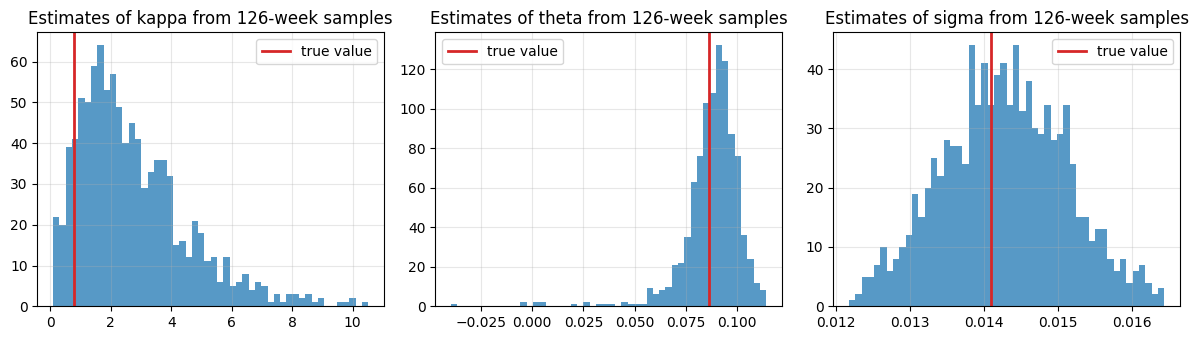

In [16]:
# Cell 16: check 4
SUB = 4                                               # simulator steps per week
def synthetic_weekly(n_weeks, n_paths, rng):
    _, _, path = simulate(r0, *params, [n_weeks / 52], 52 * SUB, n_paths, rng, keep_paths=True)
    return path[::SUB]                                # one row per week

big = synthetic_weekly(1000, 200, np.random.default_rng(SEED + 102))
k_hat, th_hat, s_hat, _ = calibrate_vasicek(big, DT_OBS)
check("4 recover kappa", abs(k_hat / kappa - 1) <= 0.10, f"true {kappa:.3f}, recovered {k_hat:.3f} ({(k_hat/kappa-1)*100:+.1f}%, tolerance 10%)")
check("4 recover theta", abs(th_hat / theta - 1) <= 0.02, f"true {theta:.4f}, recovered {th_hat:.4f} ({(th_hat/theta-1)*100:+.1f}%, tolerance 2%)")
check("4 recover sigma", abs(s_hat / sigma - 1) <= 0.02, f"true {sigma:.4f}, recovered {s_hat:.4f} ({(s_hat/sigma-1)*100:+.1f}%, tolerance 2%)")

# Same sample size as the real data
small = synthetic_weekly(len(r_obs) - 1, 1000, np.random.default_rng(SEED + 103))
est, failed = [], 0
for i in range(small.shape[1]):
    try:
        est.append(calibrate_vasicek(small[:, i], DT_OBS)[:3])
    except ValueError:
        failed += 1
est = np.array(est)
print(f"\nSamples of {len(r_obs)} weeks ({len(est)} usable, {failed} with no mean reversion detected):")
for name, true, col in [("kappa", kappa, 0), ("theta", theta, 1), ("sigma", sigma, 2)]:
    lo, med, hi = np.percentile(est[:, col], [2.5, 50, 97.5])
    print(f"  {name}: true {true:.4f} | median estimate {med:.4f} | 95% of estimates between {lo:.4f} and {hi:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, name, true, col in zip(axes, ["kappa", "theta", "sigma"], params, range(3)):
    ax.hist(est[:, col], bins=50, range=tuple(np.percentile(est[:, col], [0.5, 99.5])), color="tab:blue", alpha=0.75)
    ax.axvline(true, color="tab:red", lw=2, label="true value")
    ax.set_title(f"Estimates of {name} from {len(r_obs)}-week samples"); ax.legend()
plt.tight_layout(); plt.show()

### Check 5: Value-at-Risk and Expected Shortfall against exact values

In the Vasicek model the rate after one year is normally distributed, $r_1 \sim \mathcal N(m, s^2)$, and the bond value falls as the rate rises. The 95% VaR is therefore the loss at the rate $r_q = m + z_{0.95}\,s$, and the Expected Shortfall has the closed form

$$\text{ES} = V_0 - C - \sum_j c_j\,A_j\,e^{-B_j m + B_j^2 s^2/2}\;\frac{\Phi(-z_{0.95} - B_j s)}{1-0.95},$$

where the sum runs over the cash flows $c_j$ still to come after one year, $A_j$ and $B_j$ are evaluated at their remaining times, and $C$ is the coupons received during the year. The Monte Carlo risk engine must agree within 0.05 LKR.

In [17]:
# Cell 17: check 5
def exact_risk(r_start, params, times, amounts, horizon=HORIZON, alpha=ALPHA):
    k, th, s = params
    v0 = np.sum(amounts * vasicek_zero_price(r_start, times, k, th, s))
    later = times > horizon + 1e-9
    tau, c = times[later] - horizon, amounts[later]
    coupons = amounts[~later].sum()
    m, sd = ou_mean(r_start, horizon, k, th), np.sqrt(ou_var(horizon, k, s))
    z = stats.norm.ppf(alpha)
    var = v0 - coupons - np.sum(c * vasicek_zero_price(m + z * sd, tau, k, th, s))
    B = vasicek_B(tau, k)
    A = vasicek_zero_price(0.0, tau, k, th, s)        # price at r = 0 equals A(tau)
    tail = np.sum(c * A * np.exp(-B * m + 0.5 * (B * sd) ** 2) * stats.norm.cdf(-z - B * sd)) / (1 - alpha)
    return v0, var, v0 - coupons - tail

v0_exact, var_exact, es_exact = exact_risk(r0, params, cf_times, cf_amounts)
res = one_year_risk(r0, params, cf_times, cf_amounts, v0_exact, np.random.default_rng(SEED + 104))
TOL_RISK = 0.05           # LKR per 100 face
check("5 VaR", abs(res["VaR"] - var_exact) <= TOL_RISK, f"MC {res['VaR']:.4f}, exact {var_exact:.4f}, difference {res['VaR']-var_exact:+.4f}, tolerance {TOL_RISK}")
check("5 ES", abs(res["ES"] - es_exact) <= TOL_RISK, f"MC {res['ES']:.4f}, exact {es_exact:.4f}, difference {res['ES']-es_exact:+.4f}, tolerance {TOL_RISK}")

PASS  5 VaR: MC -8.2440, exact -8.2188, difference -0.0252, tolerance 0.05
PASS  5 ES: MC -7.7592, exact -7.7306, difference -0.0286, tolerance 0.05


### Check 6: measured error scaling

Two sources of error are measured separately on log–log axes.

**Sampling error.** Monte Carlo theory says the error of an average of $N$ paths falls as $N^{-1/2}$. One large run is cut into blocks of $N$ paths, and the root-mean-square deviation of the block averages is measured for several $N$. The fitted slope must be close to $-0.5$.

**Time-step error.** Euler–Maruyama has weak order 1, so the bias of the price should fall in proportion to $\Delta t$. The price is computed with several step sizes and compared with the exact value. The fitted slope must be close to $1$.

PASS  6a sampling error slope: fitted slope -0.503 (theory -0.5)
PASS  6b time-step error slope: fitted slope 0.981 (theory 1)


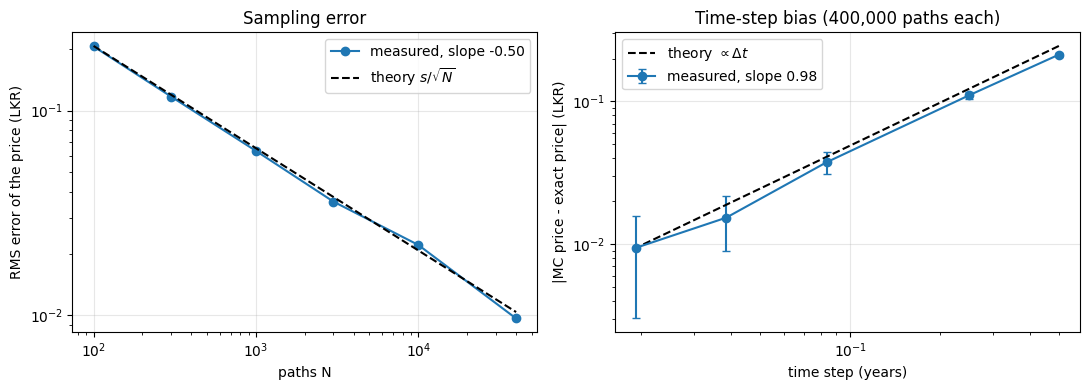

In [18]:
# Cell 18: check 6a, sampling error against number of paths
_, _, pv_all = mc_price(r0, params, zero_times, zero_amounts, 400_000, np.random.default_rng(SEED + 105))
block_sizes = np.array([100, 300, 1000, 3000, 10_000, 40_000])
rms = []
for n in block_sizes:
    block_means = pv_all[: (len(pv_all) // n) * n].reshape(-1, n).mean(axis=1)
    rms.append(np.sqrt(np.mean((block_means - pv_all.mean()) ** 2)))
rms = np.array(rms)
slope_N = np.polyfit(np.log(block_sizes), np.log(rms), 1)[0]
check("6a sampling error slope", -0.6 <= slope_N <= -0.4, f"fitted slope {slope_N:.3f} (theory -0.5)")

# Cell continues: check 6b, bias against time step
steps_list = np.array([2, 4, 12, 26, 52])
rng = np.random.default_rng(SEED + 106)
bias, bias_se = [], []
for spy in steps_list:
    m, se, _ = mc_price(r0, params, zero_times, zero_amounts, 400_000, rng, steps_per_year=int(spy))
    bias.append(m - exact_zero); bias_se.append(se)
bias, bias_se = np.array(bias), np.array(bias_se)
dts = 1.0 / steps_list
slope_dt = np.polyfit(np.log(dts), np.log(np.abs(bias)), 1)[0]
check("6b time-step error slope", 0.8 <= slope_dt <= 1.2, f"fitted slope {slope_dt:.3f} (theory 1)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].loglog(block_sizes, rms, "o-", label=f"measured, slope {slope_N:.2f}")
axes[0].loglog(block_sizes, pv_all.std(ddof=1) / np.sqrt(block_sizes), "k--", label=r"theory $s/\sqrt{N}$")
axes[0].set_xlabel("paths N"); axes[0].set_ylabel("RMS error of the price (LKR)")
axes[0].set_title("Sampling error"); axes[0].legend()
axes[1].errorbar(dts, np.abs(bias), yerr=1.96 * bias_se, fmt="o-", capsize=3, label=f"measured, slope {slope_dt:.2f}")
axes[1].loglog(dts, np.abs(bias[-1]) * dts / dts[-1], "k--", label=r"theory $\propto \Delta t$")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("time step (years)"); axes[1].set_ylabel("|MC price - exact price| (LKR)")
axes[1].set_title("Time-step bias (400,000 paths each)"); axes[1].legend()
plt.tight_layout(); plt.show()

In [19]:
# Cell 19: summary of all checks
print(f"{sum(checks.values())} of {len(checks)} checks passed")
assert all(checks.values())

16 of 16 checks passed


## 6. Experiments and results

### 6.1 Fair value of the bond

Each of the `N_SEEDS` replications uses its own random stream derived from the master seed. Two intervals are shown: the within-run 95% interval from one replication ($\pm 1.96\,s/\sqrt N$), and the 95% Student-t interval across replications.

In [20]:
# Cell 20: prices over several seeds
def ci_across(values, level=0.95):
    # mean and half-width of a Student-t confidence interval across replications
    v = np.asarray(values, dtype=float)
    half = stats.t.ppf(0.5 + level / 2, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))
    return v.mean(), half

child_seeds = np.random.SeedSequence(SEED).spawn(N_SEEDS)
zero_runs, coupon_runs = [], []
for ss in child_seeds:
    rng = np.random.default_rng(ss)
    pz, sez, _ = mc_price(r0, params, zero_times, zero_amounts, N_PATHS, rng)
    pc, sec, _ = mc_price(r0, params, cf_times, cf_amounts, N_PATHS, rng)
    zero_runs.append((pz, sez)); coupon_runs.append((pc, sec))
zero_runs, coupon_runs = np.array(zero_runs), np.array(coupon_runs)

P_zero, hw_zero = ci_across(zero_runs[:, 0])
V0, hw_V0 = ci_across(coupon_runs[:, 0])

def ytm(price, times, amounts, freq=COUPON_FREQ):
    # yield to maturity, compounded freq times a year
    f = lambda y: np.sum(amounts / (1 + y / freq) ** (times * freq)) - price
    return brentq(f, -0.5, 2.0)

print(f"Master seed {SEED}, {N_SEEDS} replications x {N_PATHS:,} paths, dt = 1/{STEPS_PER_YEAR} year")
print(f"Zero-coupon bond  : {P_zero:8.4f} +/- {hw_zero:.4f} LKR per 100 face  "
      f"(first run alone: {zero_runs[0,0]:.4f} +/- {1.96*zero_runs[0,1]:.4f})")
print(f"Coupon bond ({COUPON_RATE*100:g}%) : {V0:8.4f} +/- {hw_V0:.4f} LKR per 100 face  "
      f"(first run alone: {coupon_runs[0,0]:.4f} +/- {1.96*coupon_runs[0,1]:.4f})")
print(f"Model 5-year zero yield (continuous)      : {-np.log(P_zero/FACE)/T_BOND*100:.2f}%")
print(f"Model yield to maturity (semi-annual)     : {ytm(V0, cf_times, cf_amounts)*100:.2f}%")

Master seed 42, 10 replications x 100,000 paths, dt = 1/52 year
Zero-coupon bond  :  63.8405 +/- 0.0062 LKR per 100 face  (first run alone: 63.8411 +/- 0.0128)
Coupon bond (10%) : 103.0230 +/- 0.0075 LKR per 100 face  (first run alone: 103.0063 +/- 0.0165)
Model 5-year zero yield (continuous)      : 8.98%
Model yield to maturity (semi-annual)     : 9.23%


### 6.2 One-year Value-at-Risk and Expected Shortfall

Value today V0                         : 103.023 LKR
Expected value in one year (with coupons): 113.204 +/- 0.016 LKR
95% VaR  (loss against today's value)  : -8.219 +/- 0.017 LKR   (negative = still a gain)
95% ES                                 : -7.728 +/- 0.015 LKR
95% VaR against the expected value     : 1.962 +/- 0.009 LKR
Probability of any loss over the year  : 0.00% +/- 0.00%


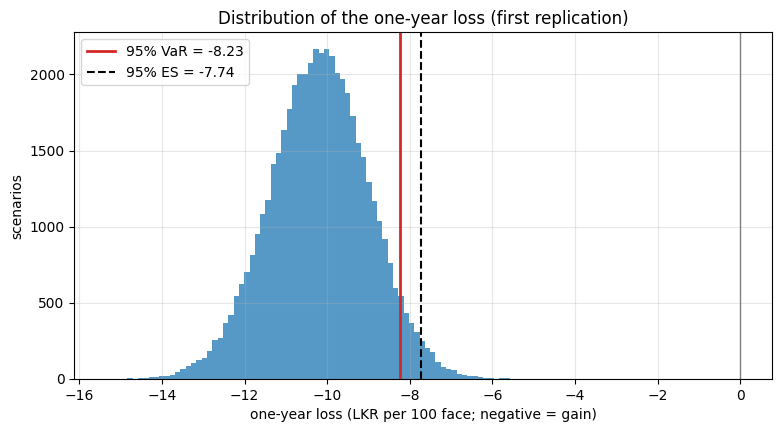

In [21]:
# Cell 21: risk over several seeds
risk_runs = []
for ss in np.random.SeedSequence(SEED + 1).spawn(N_SEEDS):
    risk_runs.append(one_year_risk(r0, params, cf_times, cf_amounts, V0, np.random.default_rng(ss)))

VaR, hw_VaR = ci_across([r["VaR"] for r in risk_runs])
ES, hw_ES = ci_across([r["ES"] for r in risk_runs])
relVaR, hw_rel = ci_across([r["rel_VaR"] for r in risk_runs])
meanV1, hw_mV1 = ci_across([r["mean_v1"] for r in risk_runs])
p_loss, hw_pl = ci_across([(r["loss"] > 0).mean() for r in risk_runs])

print(f"Value today V0                         : {V0:.3f} LKR")
print(f"Expected value in one year (with coupons): {meanV1:.3f} +/- {hw_mV1:.3f} LKR")
print(f"95% VaR  (loss against today's value)  : {VaR:.3f} +/- {hw_VaR:.3f} LKR   (negative = still a gain)")
print(f"95% ES                                 : {ES:.3f} +/- {hw_ES:.3f} LKR")
print(f"95% VaR against the expected value     : {relVaR:.3f} +/- {hw_rel:.3f} LKR")
print(f"Probability of any loss over the year  : {p_loss*100:.2f}% +/- {hw_pl*100:.2f}%")

loss = risk_runs[0]["loss"]
fig, ax = plt.subplots()
ax.hist(loss, bins=80, color="tab:blue", alpha=0.75)
ax.axvline(risk_runs[0]["VaR"], color="tab:red", lw=2, label=f"95% VaR = {risk_runs[0]['VaR']:.2f}")
ax.axvline(risk_runs[0]["ES"], color="k", ls="--", lw=1.5, label=f"95% ES = {risk_runs[0]['ES']:.2f}")
ax.axvline(0, color="grey", lw=1)
ax.set_xlabel("one-year loss (LKR per 100 face; negative = gain)"); ax.set_ylabel("scenarios")
ax.set_title("Distribution of the one-year loss (first replication)"); ax.legend()
plt.show()

### 6.3 Scenario comparison: which period is the model fitted to?

The baseline is fitted to the calm period since February 2024. The same model is refitted to three other windows and every result is recomputed from the same starting rate. This is the main experiment: it shows how far the answer depends on whether the 2022 to 2023 crisis is treated as part of normal behaviour.

In [22]:
# Cell 22: helper that prices the bond and measures its risk for one set of parameters
def run_scenario(p, model="vasicek", n_seeds=5, n_paths=50_000, n_outer=N_OUTER, n_inner=N_INNER, n_grid=N_GRID, seed=SEED + 200):
    prices, out = [], {"VaR": [], "ES": [], "p_loss": [], "p_neg": []}
    for ss in np.random.SeedSequence(seed).spawn(n_seeds):
        rng = np.random.default_rng(ss)
        price = float(mc_price(r0, p, cf_times, cf_amounts, n_paths, rng, model=model)[0])
        res = one_year_risk(r0, p, cf_times, cf_amounts, price, rng, n_outer=n_outer, n_inner=n_inner, n_grid=n_grid, model=model)
        prices.append(price)
        out["VaR"].append(res["VaR"]); out["ES"].append(res["ES"])
        out["p_loss"].append((res["loss"] > 0).mean()); out["p_neg"].append((res["r_h"] < 0).mean())
    row = {"price": ci_across(prices)}
    row.update({k: ci_across(v) for k, v in out.items()})
    row["ytm"] = ytm(row["price"][0], cf_times, cf_amounts)
    return row

def pm(pair, digits=2, scale=1.0):
    return f"{pair[0]*scale:.{digits}f} ± {pair[1]*scale:.{digits}f}"

In [23]:
# Cell 23: refit to four windows and recompute everything
windows = [("Calm period (baseline)", CAL_START),
           ("From January 2024", "2024-01-01"),
           ("Full sample incl. crisis", "2020-01-01"),
           ("2025 onwards", "2025-01-01")]
scenario_rows, scenario_params = [], {}
for label, start in windows:
    r_win = bills.loc[bills.date >= start, "r"].to_numpy()
    try:
        k, th, sg, _ = calibrate_vasicek(r_win, DT_OBS)
    except ValueError as e:
        scenario_rows.append({"Window": label, "Start": start, "Weeks": len(r_win), "kappa": "no mean reversion"})
        continue
    scenario_params[label] = (k, th, sg)
    res = run_scenario((k, th, sg))
    scenario_rows.append({"Window": label, "Start": start, "Weeks": len(r_win),
                          "kappa": f"{k:.3f}", "theta %": f"{th*100:.2f}", "sigma": f"{sg:.4f}",
                          "Price": pm(res["price"]), "YTM %": f"{res['ytm']*100:.2f}",
                          "95% VaR": pm(res["VaR"]), "95% ES": pm(res["ES"]),
                          "P(loss) %": pm(res["p_loss"], 1, 100), "P(rate<0) %": pm(res["p_neg"], 1, 100)})
scenario_table = pd.DataFrame(scenario_rows).fillna("")
print("5 replications; values are mean ± half-width of the 95% interval. Prices, VaR and ES in LKR per 100 face.")
scenario_table

5 replications; values are mean ± half-width of the 95% interval. Prices, VaR and ES in LKR per 100 face.


,Window,Start,Weeks,kappa,theta %,sigma,Price,YTM %,95% VaR,95% ES,P(loss) %,P(rate<0) %
0,Calm period (baseline),2024-02-15,126,0.766,8.62,0.0141,103.03 ± 0.02,9.23,-8.22 ± 0.02,-7.73 ± 0.03,0.0 ± 0.0,0.0 ± 0.0
1,From January 2024,2024-01-01,132,4.224,8.20,0.0181,106.11 ± 0.00,8.47,-9.09 ± 0.01,-9.03 ± 0.01,0.0 ± 0.0,0.0 ± 0.0
2,Full sample incl. crisis,2020-01-01,332,0.214,13.94,0.0509,95.13 ± 0.10,11.30,5.76 ± 0.09,9.12 ± 0.13,16.4 ± 0.2,0.9 ± 0.0
3,2025 onwards,2025-01-01,80,no mean reversion,,,,,,,,


### 6.4 Sensitivity: which input drives the answer?

Each parameter is varied on its own while the other two stay at their baseline values. The ranges are wide enough to cover both the estimation uncertainty found in Check 4 and the crisis-period estimates in 6.3. Error bars are 95% intervals over 5 replications.

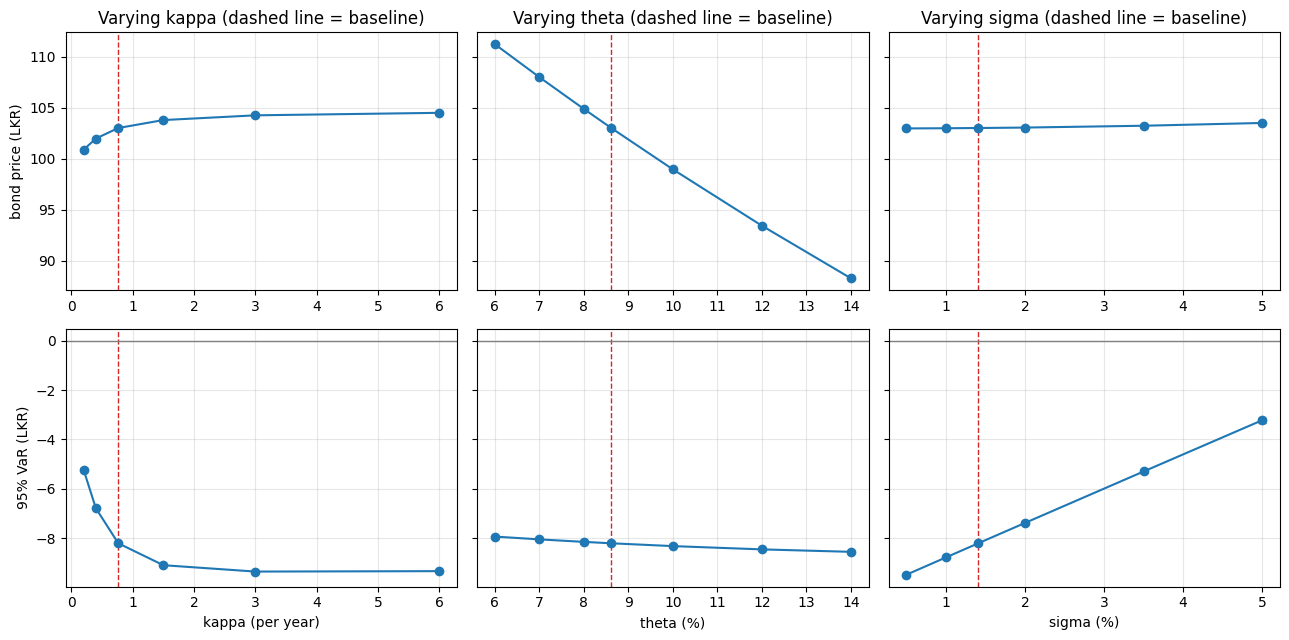

,Parameter,Range tested,Price range (LKR),Price spread,VaR range (LKR),VaR spread
0,kappa,0.2 to 6,100.90 to 104.52,3.62,-9.35 to -5.22,4.12
1,theta,0.06 to 0.14,88.30 to 111.24,22.94,-8.55 to -7.93,0.62
2,sigma,0.005 to 0.05,102.99 to 103.52,0.54,-9.47 to -3.22,6.25


In [24]:
# Cell 24: one-at-a-time sweeps
sweeps = {"kappa": np.array([0.2, 0.4, kappa, 1.5, 3.0, 6.0]),
          "theta": np.array([0.06, 0.07, 0.08, theta, 0.10, 0.12, 0.14]),
          "sigma": np.array([0.005, 0.01, sigma, 0.02, 0.035, 0.05])}
light = dict(n_seeds=5, n_paths=20_000, n_outer=20_000, n_inner=5_000, n_grid=21)
sweep_results = {}
for j, (name, values) in enumerate(sweeps.items()):
    rows = []
    for v in np.sort(values):
        p = list(params); p[j] = v
        res = run_scenario(tuple(p), **light)
        rows.append((v, *res["price"], *res["VaR"]))
    sweep_results[name] = np.array(rows)       # columns: value, price, price half-width, VaR, VaR half-width

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharey="row")
for col, name in enumerate(sweeps):
    a = sweep_results[name]
    xs = a[:, 0] * (1 if name == "kappa" else 100)
    base = params[col] * (1 if name == "kappa" else 100)
    for row, (m, h, ylabel) in enumerate([(1, 2, "bond price (LKR)"), (3, 4, "95% VaR (LKR)")]):
        ax = axes[row, col]
        ax.errorbar(xs, a[:, m], yerr=a[:, h], fmt="o-", capsize=3)
        ax.axvline(base, color="tab:red", ls="--", lw=1)
        if row == 1:
            ax.axhline(0, color="grey", lw=1)
            ax.set_xlabel(name + (" (per year)" if name == "kappa" else " (%)"))
        if col == 0:
            ax.set_ylabel(ylabel)
    axes[0, col].set_title(f"Varying {name} (dashed line = baseline)")
plt.tight_layout(); plt.show()

sens = pd.DataFrame([{"Parameter": n, "Range tested": f"{a[0,0]:.3g} to {a[-1,0]:.3g}",
                      "Price range (LKR)": f"{a[:,1].min():.2f} to {a[:,1].max():.2f}", "Price spread": round(np.ptp(a[:, 1]), 2),
                      "VaR range (LKR)": f"{a[:,3].min():.2f} to {a[:,3].max():.2f}", "VaR spread": round(np.ptp(a[:, 3]), 2)}
                     for n, a in sweep_results.items()])
sens

### 6.5 Comparison with real 5-year bond auctions

For every week in the calibration window in which a 5-year Treasury bond was auctioned, the model's 5-year par yield is computed from that week's short rate and compared with the published auction yield. The par yield is the coupon rate at which a new 5-year bond would be worth exactly its face value:

$$y_{\text{par}} = \frac{2\,\big(1 - P(0,5)\big)}{\sum_{j=1}^{10} P(0, t_j)} .$$

18 auctions from 2024-02-15 to 2026-01-01
Observed minus model: mean 2.15 ± 0.56 percentage points, RMSE 2.41


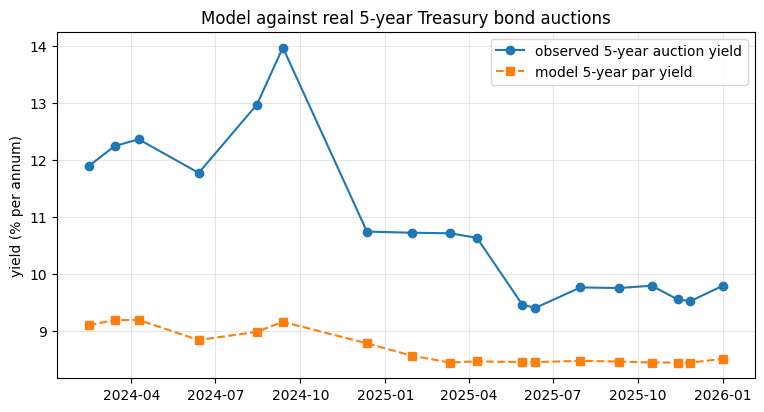

In [25]:
# Cell 25: model par yield against observed 5-year auction yields
auct = raw.dropna(subset=["bond_5y"])[["date", "bond_5y"]]
auct = auct[auct.date >= CAL_START]
auct = pd.merge_asof(auct.sort_values("date"), bills[["date", "r"]].sort_values("date"), on="date", direction="backward")

half_years = np.arange(1, int(T_BOND * 2) + 1) / 2
D, _ = simulate(auct["r"].to_numpy()[:, None], *params, half_years, STEPS_PER_YEAR, 50_000, np.random.default_rng(SEED + 300))
P = D.mean(axis=1)                                   # discount factors, one row per auction date
auct["model"] = 2 * (1 - P[:, -1]) / P.sum(axis=1) * 100
auct["gap"] = auct["bond_5y"] - auct["model"]

gap_mean, gap_hw = ci_across(auct["gap"])
rmse = np.sqrt(np.mean(auct["gap"] ** 2))
print(f"{len(auct)} auctions from {auct.date.min().date()} to {auct.date.max().date()}")
print(f"Observed minus model: mean {gap_mean:.2f} ± {gap_hw:.2f} percentage points, RMSE {rmse:.2f}")

fig, ax = plt.subplots()
ax.plot(auct.date, auct.bond_5y, "o-", label="observed 5-year auction yield")
ax.plot(auct.date, auct.model, "s--", label="model 5-year par yield")
ax.set_ylabel("yield (% per annum)"); ax.set_title("Model against real 5-year Treasury bond auctions"); ax.legend()
plt.show()

### 6.6 Extension: the Cox–Ingersoll–Ross model

The Vasicek model allows negative rates and keeps the same volatility at every rate level. The Cox–Ingersoll–Ross (CIR) model scales the noise by $\sqrt{r_t}$, so shocks shrink as the rate approaches zero:

$$dr_t = \kappa(\theta - r_t)\,dt + \sigma\sqrt{r_t}\,dW_t .$$

It is simulated with the full-truncation Euler scheme, which replaces $r$ by $\max(r,0)$ inside the drift and the square root. It is calibrated by least squares on the Euler form divided by $\sqrt{r_t}$:

$$\frac{r_{t+\Delta}-r_t}{\sqrt{r_t}} = \kappa\theta\,\frac{\Delta}{\sqrt{r_t}} - \kappa\,\Delta\sqrt{r_t} + \sigma\sqrt{\Delta}\;\varepsilon_t .$$

CIR also has an exact bond price, used here to verify the simulation. With $\gamma = \sqrt{\kappa^2 + 2\sigma^2}$:

$$P(r,\tau) = A(\tau)e^{-B(\tau) r},\quad
B(\tau) = \frac{2(e^{\gamma\tau}-1)}{(\gamma+\kappa)(e^{\gamma\tau}-1)+2\gamma},\quad
A(\tau) = \left[\frac{2\gamma\,e^{(\kappa+\gamma)\tau/2}}{(\gamma+\kappa)(e^{\gamma\tau}-1)+2\gamma}\right]^{2\kappa\theta/\sigma^2}.$$

In [26]:
# Cell 26: CIR calibration, exact price and verification
def calibrate_cir(r, dt):
    x = r[:-1]
    y = (r[1:] - x) / np.sqrt(x)
    X = np.column_stack([dt / np.sqrt(x), -dt * np.sqrt(x)])      # coefficients: kappa*theta and kappa
    (kt, k), *_ = np.linalg.lstsq(X, y, rcond=None)
    if k <= 0:
        raise ValueError("no mean reversion in this window")
    resid = y - X @ np.array([kt, k])
    return k, kt / k, resid.std(ddof=2) / np.sqrt(dt)

def cir_zero_price(r, tau, kappa, theta, sigma):
    g = np.sqrt(kappa**2 + 2 * sigma**2)
    denom = (g + kappa) * (np.exp(g * tau) - 1) + 2 * g
    B = 2 * (np.exp(g * tau) - 1) / denom
    A = (2 * g * np.exp((kappa + g) * tau / 2) / denom) ** (2 * kappa * theta / sigma**2)
    return A * np.exp(-B * r)

cir_params = calibrate_cir(r_obs, DT_OBS)
kc, thc, sc = cir_params
print(f"CIR: kappa = {kc:.3f} per year, theta = {thc*100:.2f}%, sigma = {sc:.4f}")
print(f"Feller condition 2*kappa*theta >= sigma^2: {2*kc*thc:.4f} >= {sc**2:.4f} -> {2*kc*thc >= sc**2} (rate stays positive)")

exact_cir = FACE * cir_zero_price(r0, T_BOND, *cir_params)
D, _ = simulate(r0, *cir_params, [T_BOND], FINE_STEPS, N_PATHS, np.random.default_rng(SEED + 400), model="cir")
pv = FACE * D[:, 0]
check("7a CIR price, fine step", abs(pv.mean() - exact_cir) <= 3 * pv.std(ddof=1) / np.sqrt(N_PATHS),
      f"MC {pv.mean():.4f}, exact {exact_cir:.4f}, 3 SE = {3*pv.std(ddof=1)/np.sqrt(N_PATHS):.4f}")
m, se, _ = mc_price(r0, cir_params, zero_times, zero_amounts, 4 * N_PATHS, np.random.default_rng(SEED + 401), model="cir")
check("7b CIR price, weekly step", abs(m - exact_cir) <= TOL_PRICE, f"MC {m:.4f}, exact {exact_cir:.4f}, difference {m-exact_cir:+.4f}, tolerance {TOL_PRICE}")

CIR: kappa = 0.678 per year, theta = 8.64%, sigma = 0.0470
Feller condition 2*kappa*theta >= sigma^2: 0.1172 >= 0.0022 -> True (rate stays positive)
PASS  7a CIR price, fine step: MC 63.6436, exact 63.6359, 3 SE = 0.0215
PASS  7b CIR price, weekly step: MC 63.6448, exact 63.6359, difference +0.0089, tolerance 0.05


In [27]:
# Cell 27: Vasicek and CIR side by side
model_rows = []
for label, p, model in [("Vasicek", params, "vasicek"), ("CIR", cir_params, "cir")]:
    res = run_scenario(p, model=model)
    model_rows.append({"Model": label, "kappa": f"{p[0]:.3f}", "theta %": f"{p[1]*100:.2f}", "sigma": f"{p[2]:.4f}",
                       "Price": pm(res["price"]), "YTM %": f"{res['ytm']*100:.2f}",
                       "95% VaR": pm(res["VaR"]), "95% ES": pm(res["ES"]), "P(loss) %": pm(res["p_loss"], 1, 100)})
model_table = pd.DataFrame(model_rows)
model_table

,Model,kappa,theta %,sigma,Price,YTM %,95% VaR,95% ES,P(loss) %
0,Vasicek,0.766,8.62,0.0141,103.03 ± 0.02,9.23,-8.22 ± 0.02,-7.73 ± 0.03,0.0 ± 0.0
1,CIR,0.678,8.64,0.0470,102.77 ± 0.02,9.29,-7.84 ± 0.02,-7.20 ± 0.03,0.0 ± 0.0


### 6.7 Answer to the question

In [28]:
# Cell 28: headline numbers gathered in one place
print(f"All {len(checks)} verification checks passed: {all(checks.values())}")
print(f"\nBaseline (calm period from {CAL_START}; kappa {kappa:.3f}, theta {theta*100:.2f}%, sigma {sigma:.4f}; r0 {r0*100:.2f}%)")
print(f"  Fair value of the 5-year {COUPON_RATE*100:g}% bond : {V0:.2f} ± {hw_V0:.2f} LKR per 100 face (yield to maturity {ytm(V0, cf_times, cf_amounts)*100:.2f}%)")
print(f"  One-year 95% VaR                : {VaR:.2f} ± {hw_VaR:.2f} LKR  ({'a gain even in the worst 5% of scenarios' if VaR < 0 else 'a loss'})")
print(f"  One-year 95% ES                 : {ES:.2f} ± {hw_ES:.2f} LKR")
print(f"  95% VaR against expected value  : {relVaR:.2f} ± {hw_rel:.2f} LKR")
print(f"\nMarket check: observed 5-year auction yields exceed the model by {gap_mean:.2f} ± {gap_hw:.2f} percentage points on average.")
print("\nSame bond, model refitted to other periods:")
print(scenario_table[["Window", "Price", "95% VaR", "95% ES", "P(loss) %"]].to_string(index=False))

All 18 verification checks passed: True

Baseline (calm period from 2024-02-15; kappa 0.766, theta 8.62%, sigma 0.0141; r0 10.08%)
  Fair value of the 5-year 10% bond : 103.02 ± 0.01 LKR per 100 face (yield to maturity 9.23%)
  One-year 95% VaR                : -8.22 ± 0.02 LKR  (a gain even in the worst 5% of scenarios)
  One-year 95% ES                 : -7.73 ± 0.01 LKR
  95% VaR against expected value  : 1.96 ± 0.01 LKR

Market check: observed 5-year auction yields exceed the model by 2.15 ± 0.56 percentage points on average.

Same bond, model refitted to other periods:
                  Window         Price      95% VaR       95% ES  P(loss) %
  Calm period (baseline) 103.03 ± 0.02 -8.22 ± 0.02 -7.73 ± 0.03  0.0 ± 0.0
       From January 2024 106.11 ± 0.00 -9.09 ± 0.01 -9.03 ± 0.01  0.0 ± 0.0
Full sample incl. crisis  95.13 ± 0.10  5.76 ± 0.09  9.12 ± 0.13 16.4 ± 0.2
            2025 onwards                                                   


## 7. Discussion and limitations

**Answer.** Fitted to the calm period since February 2024, the model values the 5-year bond slightly above its face value and finds no loss over one year at 95% confidence: the income earned in a year is several times larger than the fall in price caused by an adverse rate move. Under this calibration the Value-at-Risk measured against today's value is negative, which means a gain. The risk only appears as a shortfall against the expected value.

**The answer depends on the calibration period.** Section 6.3 refits the same model to other windows. When the 2022 to 2023 crisis is included, volatility is several times higher, mean reversion is much slower, and the same bond shows a real loss at 95% confidence. The honest answer to the question is therefore conditional: little or no loss if rates keep behaving as they have since early 2024, and a substantial loss if crisis-like behaviour returns.

**Which inputs matter.** Section 6.4 shows that the long-run rate $\theta$ moves the price most, while the volatility $\sigma$ and the speed of mean reversion $\kappa$ decide the risk figures. Check 4 shows that $\kappa$ is also the parameter the data determine worst: with about two and a half years of weekly observations its estimate is strongly biased upwards and spread over a wide range.

**Limitations.**

1. *Constant parameters.* One set of parameters cannot describe a calm regime and a crisis. The model has no way to move between them.
2. *Non-normal shocks.* The 91-day yield stays flat for long stretches and then jumps; the largest weekly residual is about six standard deviations. The model assumes normally distributed shocks, so it understates sudden moves.
3. *No risk premium.* Section 6.5 shows observed 5-year auction yields sitting above the model's yields. Investors require extra return for holding a long bond, and the model leaves it out, so the model price is too high compared with the market.
4. *Short-rate proxy.* A 91-day auction yield is not an instantaneous rate, and auction outcomes reflect debt-management decisions as well as market forces.
5. *Negative rates.* Vasicek allows them. They are negligible in the baseline but not under the crisis calibration. The CIR extension in 6.6 removes them.
6. *Estimation uncertainty.* The risk figures are reported with Monte Carlo confidence intervals, which measure simulation error only. Uncertainty in the parameters themselves is larger.
7. *Discretisation.* The weekly time step adds a small bias to prices, measured in Checks 1 and 6 and well inside the stated tolerance.
8. *No credit risk.* Every cash flow is assumed to be paid in full.

**Possible extensions.** A risk premium fitted to the auction yields, a regime-switching or jump model, and parameter uncertainty carried through to the risk figures by bootstrap or Bayesian estimation.

## 8. References

[1] O. Vasicek, "An equilibrium characterization of the term structure," *J. Financ. Econ.*, vol. 5, no. 2, pp. 177–188, 1977, doi: 10.1016/0304-405X(77)90016-2.

[2] P. Glasserman, *Monte Carlo Methods in Financial Engineering*. New York, NY, USA: Springer, 2003.

[3] P. P. Boyle, "Options: A Monte Carlo approach," *J. Financ. Econ.*, vol. 4, no. 3, pp. 323–338, 1977, doi: 10.1016/0304-405X(77)90005-8.

[4] P. E. Kloeden and E. Platen, *Numerical Solution of Stochastic Differential Equations*. Berlin, Germany: Springer, 1992.

[5] J. C. Cox, J. E. Ingersoll and S. A. Ross, "A theory of the term structure of interest rates," *Econometrica*, vol. 53, no. 2, pp. 385–407, 1985, doi: 10.2307/1911242.

[6] Central Bank of Sri Lanka, "Rates on Government Securities," Data Library. [Online]. Available: https://www.cbsl.lk/eResearch/MoneyMarketRatesDefault.aspx?ReportId=6169

In [29]:
# Cell 29: total run time
print(f"Total run time: {time.time() - T_START:.0f} s")

Total run time: 205 s
